# 02 — Baseline Modeling

**Date:** September 14, 2026

## Objective

Build and evaluate a baseline model to predict late-delivery risk at the order level while preserving the chronological train, validation, and test split.

The test set will remain locked until the final model and decision threshold have been selected.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

pd.set_option("display.max_columns", None)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Pandas version: 3.0.5
NumPy version: 2.5.3
Scikit-learn version: 1.9.1


In [2]:
current_dir = Path.cwd()

project_root = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

feature_mart_path = (
    project_root
    / "outputs"
    / "feature_mart_order_level.csv"
)

df = pd.read_csv(
    feature_mart_path,
    parse_dates=["order_datetime"]
)

print("File found:", feature_mart_path.exists())
print("Dataset shape:", df.shape)
print("Unique order IDs:", df["order_id"].nunique())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())

display(
    df["data_split"]
    .value_counts()
    .rename_axis("data_split")
    .reset_index(name="order_count")
)

File found: True
Dataset shape: (65752, 33)
Unique order IDs: 65752
Duplicate order IDs: 0
Missing values: 0


,data_split,order_count
0,train,41763
1,test,13670
2,validation,10319


## 1. Chronological Data Split

The dataset is divided chronologically to replicate a real forecasting scenario and prevent future information from influencing model development.

- **Training:** January 2015–December 2016
- **Validation:** January 2017–June 2017
- **Test:** July 2017–January 2018

The test set remains locked until the model and decision threshold are finalized.

In [3]:
train_df = df.loc[df["data_split"] == "train"].copy()
validation_df = df.loc[df["data_split"] == "validation"].copy()
test_df = df.loc[df["data_split"] == "test"].copy()

chronological_order_verified = (
    train_df["order_datetime"].max()
    < validation_df["order_datetime"].min()
    < test_df["order_datetime"].min()
)

development_summary = pd.DataFrame({
    "data_split": ["train", "validation"],
    "row_count": [len(train_df), len(validation_df)],
    "start_date": [
        train_df["order_datetime"].min(),
        validation_df["order_datetime"].min()
    ],
    "end_date": [
        train_df["order_datetime"].max(),
        validation_df["order_datetime"].max()
    ],
    "late_delivery_rate_pct": [
        train_df["late_delivery_risk"].mean() * 100,
        validation_df["late_delivery_risk"].mean() * 100
    ]
})

print("Chronological order verified:", chronological_order_verified)
print("Locked test rows:", len(test_df))

display(development_summary)

Chronological order verified: True
Locked test rows: 13670


,data_split,row_count,start_date,end_date,late_delivery_rate_pct
0,train,41763,2015-01-01 00:00:00,2016-12-31 23:51:00,54.900271
1,validation,10319,2017-01-01 00:33:00,2017-06-30 23:25:00,54.230061


## 2. Target and Operational Feature Set

The target is `late_delivery_risk`, where:

- `1` indicates a late delivery.
- `0` indicates an on-time or early delivery.

The initial model uses information available when the order is created. Identifiers, raw timestamps, split labels, detailed high-cardinality geography, and potential post-order profitability variables are excluded.

Profitability variables will be evaluated separately in an extended model because their availability at prediction time must be confirmed with the business.

In [4]:
target_column = "late_delivery_risk"

categorical_features = [
    "payment_type",
    "customer_segment",
    "shipping_mode",
    "market",
    "order_region",
    "order_country",
    "primary_department"
]

numeric_features = [
    "order_month",
    "order_quarter",
    "order_day_of_week",
    "order_hour",
    "is_weekend",
    "order_line_count",
    "total_item_quantity",
    "distinct_products",
    "distinct_categories",
    "distinct_departments",
    "gross_sales",
    "total_discount",
    "net_sales",
    "weighted_avg_unit_price",
    "order_discount_rate",
    "primary_category_sales_share"
]

model_features = categorical_features + numeric_features

X_train = train_df[model_features].copy()
y_train = train_df[target_column].copy()

X_validation = validation_df[model_features].copy()
y_validation = validation_df[target_column].copy()

print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))
print("Total model features:", len(model_features))
print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Missing values:", X_train.isna().sum().sum())

Categorical features: 7
Numeric features: 16
Total model features: 23
Training shape: (41763, 23)
Validation shape: (10319, 23)
Missing values: 0


## 3. Naive Baseline

A `DummyClassifier` establishes the minimum performance benchmark by predicting the most frequent class observed in the training data.

Any useful predictive model should outperform this baseline, particularly in discrimination metrics such as ROC AUC and balanced accuracy.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

dummy_model = DummyClassifier(
    strategy="prior",
    random_state=42
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_validation)
dummy_probabilities = dummy_model.predict_proba(X_validation)[:, 1]

dummy_metrics = pd.DataFrame({
    "model": ["DummyClassifier"],
    "roc_auc": [
        roc_auc_score(y_validation, dummy_probabilities)
    ],
    "average_precision": [
        average_precision_score(
            y_validation,
            dummy_probabilities
        )
    ],
    "accuracy": [
        accuracy_score(y_validation, dummy_predictions)
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(
            y_validation,
            dummy_predictions
        )
    ],
    "precision": [
        precision_score(
            y_validation,
            dummy_predictions,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_validation,
            dummy_predictions,
            zero_division=0
        )
    ],
    "f1": [
        f1_score(
            y_validation,
            dummy_predictions,
            zero_division=0
        )
    ]
})

display(dummy_metrics.round(4))

display(
    pd.Series(dummy_predictions)
    .value_counts()
    .sort_index()
    .rename_axis("predicted_class")
    .reset_index(name="order_count")
)

,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,DummyClassifier,0.5,0.5423,0.5423,0.5,0.5423,1.0,0.7032


,predicted_class,order_count
0,1,10319


## 4. Preprocessing Pipeline

Categorical variables are converted into numeric indicators using one-hot encoding. Previously unseen validation categories are safely ignored.

Numeric variables are standardized using parameters learned exclusively from the training set. This prevents validation information from influencing model training.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

X_train_processed = preprocessor.fit_transform(X_train)
X_validation_processed = preprocessor.transform(X_validation)

encoded_feature_names = preprocessor.get_feature_names_out()

print("Original feature count:", X_train.shape[1])
print("Encoded feature count:", len(encoded_feature_names))
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_validation_processed.shape)

Original feature count: 23
Encoded feature count: 225
Processed training shape: (41763, 225)
Processed validation shape: (10319, 225)


## 5. Interpretable Baseline Model

Logistic regression is used as the first learnable model because it provides an interpretable and reproducible benchmark.

The preprocessing and classifier are combined into a single pipeline to ensure that identical transformations are applied during training, validation, and future scoring.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_validation)
logistic_probabilities = logistic_pipeline.predict_proba(
    X_validation
)[:, 1]

logistic_metrics = pd.DataFrame({
    "model": ["LogisticRegression"],
    "roc_auc": [
        roc_auc_score(
            y_validation,
            logistic_probabilities
        )
    ],
    "average_precision": [
        average_precision_score(
            y_validation,
            logistic_probabilities
        )
    ],
    "accuracy": [
        accuracy_score(
            y_validation,
            logistic_predictions
        )
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(
            y_validation,
            logistic_predictions
        )
    ],
    "precision": [
        precision_score(
            y_validation,
            logistic_predictions,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_validation,
            logistic_predictions,
            zero_division=0
        )
    ],
    "f1": [
        f1_score(
            y_validation,
            logistic_predictions,
            zero_division=0
        )
    ]
})

model_comparison = pd.concat(
    [dummy_metrics, logistic_metrics],
    ignore_index=True
)

display(model_comparison.round(4))

display(
    pd.Series(logistic_predictions)
    .value_counts()
    .sort_index()
    .rename_axis("predicted_class")
    .reset_index(name="order_count")
)

,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,DummyClassifier,0.5000,0.5423,0.5423,0.5000,0.5423,1.0000,0.7032
1,LogisticRegression,0.7364,0.8077,0.6982,0.7116,0.8341,0.5536,0.6655


,predicted_class,order_count
0,0,6605
1,1,3714


## 6. Error Analysis at the Default Threshold

The default probability threshold of 0.50 is evaluated using a confusion matrix.

For this use case, false negatives are operationally important because they represent late deliveries that were not identified in advance.

,Predicted: Not late,Predicted: Late
Actual: Not late,4107,616
Actual: Late,2498,3098


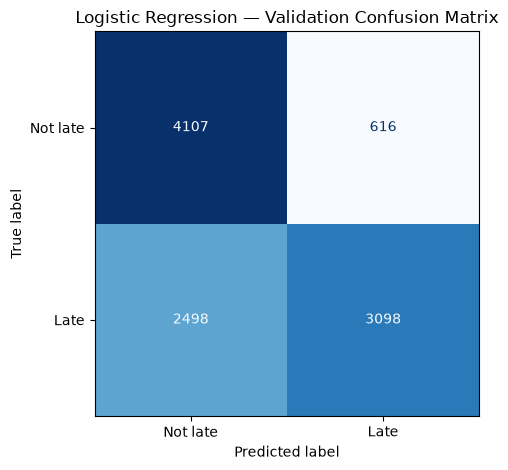

In [8]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

confusion = confusion_matrix(
    y_validation,
    logistic_predictions
)

confusion_table = pd.DataFrame(
    confusion,
    index=["Actual: Not late", "Actual: Late"],
    columns=["Predicted: Not late", "Predicted: Late"]
)

display(confusion_table)

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    logistic_predictions,
    display_labels=["Not late", "Late"],
    cmap="Blues",
    colorbar=False
)

plt.title(
    "Logistic Regression — Validation Confusion Matrix"
)
plt.tight_layout()
plt.show()

## 7. Decision-Threshold Analysis

Classification probabilities must be converted into operational alerts using a decision threshold.

Candidate thresholds are evaluated on the validation set by comparing recall, precision, balanced accuracy, false negatives, false positives, and the percentage of orders requiring intervention. The test set remains untouched.

In [9]:
threshold_rows = []

for threshold in np.arange(0.20, 0.81, 0.05):
    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "threshold": threshold,
        "alert_rate_pct": predictions.mean() * 100,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_validation,
            predictions
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

threshold_results = pd.DataFrame(threshold_rows)

display(
    threshold_results.round({
        "threshold": 2,
        "alert_rate_pct": 2,
        "precision": 4,
        "recall": 4,
        "balanced_accuracy": 4
    })
)

,threshold,alert_rate_pct,precision,recall,balanced_accuracy,false_positives,false_negatives
0,0.20,99.94,0.5425,0.9998,0.5004,4718,1
1,0.25,98.92,0.5451,0.9943,0.5055,4644,32
2,0.30,91.47,0.5609,0.9460,0.5342,4145,302
3,0.35,81.12,0.5868,0.8778,0.5727,3459,684
4,0.40,64.23,0.6399,0.7579,0.6262,2387,1355
5,0.45,44.60,0.7529,0.6192,0.6892,1137,2131
6,0.50,35.99,0.8341,0.5536,0.7116,616,2498
7,0.55,34.46,0.8394,0.5334,0.7063,571,2611
8,0.60,34.26,0.8407,0.5311,0.7059,563,2624
9,0.65,33.94,0.8418,0.5268,0.7048,554,2648


## 8. Nonlinear Challenger Model

A Histogram-Based Gradient Boosting classifier is evaluated as a nonlinear challenger.

Unlike logistic regression, this model can capture interactions and nonlinear relationships among order characteristics. Categorical variables are ordinal-encoded and explicitly identified as categorical, preventing the model from treating their codes as continuous quantities.

The same chronological validation period is used for an unbiased model comparison.

In [10]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier
)
from sklearn.preprocessing import OrdinalEncoder

hist_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ],
    remainder="drop"
)

categorical_mask = (
    [True] * len(categorical_features)
    + [False] * len(numeric_features)
)

hist_pipeline = Pipeline(
    steps=[
        ("preprocessor", hist_preprocessor),
        (
            "classifier",
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=200,
                max_leaf_nodes=31,
                min_samples_leaf=30,
                l2_regularization=1.0,
                categorical_features=categorical_mask,
                early_stopping=False,
                random_state=42
            )
        )
    ]
)

hist_pipeline.fit(X_train, y_train)

hist_predictions = hist_pipeline.predict(X_validation)
hist_probabilities = hist_pipeline.predict_proba(
    X_validation
)[:, 1]

hist_metrics = pd.DataFrame({
    "model": ["HistGradientBoosting"],
    "roc_auc": [
        roc_auc_score(y_validation, hist_probabilities)
    ],
    "average_precision": [
        average_precision_score(
            y_validation,
            hist_probabilities
        )
    ],
    "accuracy": [
        accuracy_score(y_validation, hist_predictions)
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(
            y_validation,
            hist_predictions
        )
    ],
    "precision": [
        precision_score(
            y_validation,
            hist_predictions,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_validation,
            hist_predictions,
            zero_division=0
        )
    ],
    "f1": [
        f1_score(
            y_validation,
            hist_predictions,
            zero_division=0
        )
    ]
})

model_comparison = pd.concat(
    [dummy_metrics, logistic_metrics, hist_metrics],
    ignore_index=True
)

display(model_comparison.round(4))

,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,DummyClassifier,0.5000,0.5423,0.5423,0.5000,0.5423,1.0000,0.7032
1,LogisticRegression,0.7364,0.8077,0.6982,0.7116,0.8341,0.5536,0.6655
2,HistGradientBoosting,0.7589,0.8251,0.7090,0.7198,0.8215,0.5920,0.6881


## 9. Expanding-Window Temporal Backtesting

Model stability is evaluated across multiple chronological validation windows.

Each fold trains on all information available before the validation period and predicts the following six months. This expanding-window design reflects how the model would be retrained and evaluated in production.

The final test period remains locked.

In [11]:
development_df = df.loc[
    df["data_split"].isin(["train", "validation"])
].copy()

temporal_folds = [
    {
        "fold": "Fold 1",
        "train_end": pd.Timestamp("2016-01-01"),
        "validation_start": pd.Timestamp("2016-01-01"),
        "validation_end": pd.Timestamp("2016-07-01")
    },
    {
        "fold": "Fold 2",
        "train_end": pd.Timestamp("2016-07-01"),
        "validation_start": pd.Timestamp("2016-07-01"),
        "validation_end": pd.Timestamp("2017-01-01")
    },
    {
        "fold": "Fold 3",
        "train_end": pd.Timestamp("2017-01-01"),
        "validation_start": pd.Timestamp("2017-01-01"),
        "validation_end": pd.Timestamp("2017-07-01")
    }
]

fold_summary_rows = []

for fold in temporal_folds:
    fold_train = development_df.loc[
        development_df["order_datetime"]
        < fold["train_end"]
    ]

    fold_validation = development_df.loc[
        (
            development_df["order_datetime"]
            >= fold["validation_start"]
        )
        & (
            development_df["order_datetime"]
            < fold["validation_end"]
        )
    ]

    fold_summary_rows.append({
        "fold": fold["fold"],
        "training_end": fold["train_end"],
        "training_rows": len(fold_train),
        "validation_start": fold["validation_start"],
        "validation_end": fold["validation_end"],
        "validation_rows": len(fold_validation),
        "validation_late_rate_pct": (
            fold_validation[target_column].mean() * 100
        )
    })

fold_summary = pd.DataFrame(fold_summary_rows)

fold_summary["validation_late_rate_pct"] = (
    fold_summary["validation_late_rate_pct"].round(2)
)

display(fold_summary)

,fold,training_end,training_rows,validation_start,validation_end,validation_rows,validation_late_rate_pct
0,Fold 1,2016-01-01,20904,2016-01-01,2016-07-01,10345,55.51
1,Fold 2,2016-07-01,31249,2016-07-01,2017-01-01,10514,54.74
2,Fold 3,2017-01-01,41763,2017-01-01,2017-07-01,10319,54.23


### Backtesting Results

Logistic Regression and Histogram-Based Gradient Boosting are compared across the same expanding temporal windows using a fixed 0.50 decision threshold.

In [12]:
from sklearn.base import clone

candidate_models = {
    "LogisticRegression": logistic_pipeline,
    "HistGradientBoosting": hist_pipeline
}

backtest_rows = []

for fold in temporal_folds:
    fold_train = development_df.loc[
        development_df["order_datetime"]
        < fold["train_end"]
    ]

    fold_validation = development_df.loc[
        (
            development_df["order_datetime"]
            >= fold["validation_start"]
        )
        & (
            development_df["order_datetime"]
            < fold["validation_end"]
        )
    ]

    X_fold_train = fold_train[model_features]
    y_fold_train = fold_train[target_column]

    X_fold_validation = fold_validation[model_features]
    y_fold_validation = fold_validation[target_column]

    for model_name, model_template in candidate_models.items():
        fold_model = clone(model_template)

        fold_model.fit(
            X_fold_train,
            y_fold_train
        )

        fold_probabilities = fold_model.predict_proba(
            X_fold_validation
        )[:, 1]

        fold_predictions = (
            fold_probabilities >= 0.50
        ).astype(int)

        backtest_rows.append({
            "fold": fold["fold"],
            "model": model_name,
            "roc_auc": roc_auc_score(
                y_fold_validation,
                fold_probabilities
            ),
            "average_precision": average_precision_score(
                y_fold_validation,
                fold_probabilities
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_fold_validation,
                fold_predictions
            ),
            "precision": precision_score(
                y_fold_validation,
                fold_predictions,
                zero_division=0
            ),
            "recall": recall_score(
                y_fold_validation,
                fold_predictions,
                zero_division=0
            ),
            "f1": f1_score(
                y_fold_validation,
                fold_predictions,
                zero_division=0
            )
        })

backtest_results = pd.DataFrame(backtest_rows)

display(
    backtest_results.round({
        "roc_auc": 4,
        "average_precision": 4,
        "balanced_accuracy": 4,
        "precision": 4,
        "recall": 4,
        "f1": 4
    })
)

,fold,model,roc_auc,average_precision,balanced_accuracy,precision,recall,f1
0,Fold 1,LogisticRegression,0.7390,0.8159,0.7144,0.8463,0.5543,0.6699
1,Fold 1,HistGradientBoosting,0.7637,0.8330,0.7254,0.8398,0.5916,0.6942
2,Fold 2,LogisticRegression,0.7502,0.8212,0.7175,0.8528,0.5498,0.6686
3,Fold 2,HistGradientBoosting,0.7765,0.8393,0.7320,0.8525,0.5866,0.6950
4,Fold 3,LogisticRegression,0.7364,0.8077,0.7116,0.8341,0.5536,0.6655
5,Fold 3,HistGradientBoosting,0.7589,0.8251,0.7198,0.8215,0.5920,0.6881


### Model Stability Summary

Mean performance represents expected behavior across time, while standard deviation measures temporal variability. The minimum ROC AUC provides a conservative view of the model's weakest observed period.

In [13]:
backtest_summary = (
    backtest_results
    .groupby("model")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        roc_auc_min=("roc_auc", "min"),
        average_precision_mean=(
            "average_precision",
            "mean"
        ),
        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean"
        ),
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean")
    )
    .reset_index()
)

display(
    backtest_summary.round({
        "roc_auc_mean": 4,
        "roc_auc_std": 4,
        "roc_auc_min": 4,
        "average_precision_mean": 4,
        "balanced_accuracy_mean": 4,
        "precision_mean": 4,
        "recall_mean": 4,
        "f1_mean": 4
    })
)

,model,roc_auc_mean,roc_auc_std,roc_auc_min,average_precision_mean,balanced_accuracy_mean,precision_mean,recall_mean,f1_mean
0,HistGradientBoosting,0.7664,0.0091,0.7589,0.8325,0.7257,0.8379,0.5901,0.6924
1,LogisticRegression,0.7419,0.0074,0.7364,0.8150,0.7145,0.8444,0.5526,0.6680


## 10. Feature-Set Ablation and Governance

Three progressively richer feature sets are evaluated using the same model and temporal backtesting design:

1. **Operational Core:** variables expected to be available when the order is created.
2. **Operational + Category Detail:** adds the detailed primary product category.
3. **Extended + Profitability:** adds profit and margin information whose availability at prediction time requires business confirmation.

Performance improvements do not automatically justify deployment. Feature availability, governance, and leakage risk must also be considered.

In [14]:
feature_sets = {
    "Operational Core": {
        "categorical": categorical_features.copy(),
        "numeric": numeric_features.copy()
    },
    "Operational + Category Detail": {
        "categorical": (
            categorical_features
            + ["primary_category_label"]
        ),
        "numeric": numeric_features.copy()
    },
    "Extended + Profitability": {
        "categorical": (
            categorical_features
            + ["primary_category_label"]
        ),
        "numeric": (
            numeric_features
            + ["total_profit", "order_profit_margin"]
        )
    }
}

feature_set_summary = pd.DataFrame([
    {
        "feature_set": feature_set_name,
        "categorical_features": len(features["categorical"]),
        "numeric_features": len(features["numeric"]),
        "total_features": (
            len(features["categorical"])
            + len(features["numeric"])
        )
    }
    for feature_set_name, features in feature_sets.items()
])

display(feature_set_summary)

,feature_set,categorical_features,numeric_features,total_features
0,Operational Core,7,16,23
1,Operational + Category Detail,8,16,24
2,Extended + Profitability,8,18,26


### Ablation Backtesting Results

Each feature set is evaluated with an independently trained Histogram-Based Gradient Boosting model across the three temporal folds.

Threshold-independent metrics are prioritized when assessing incremental predictive value because the operational decision threshold will be selected separately.

In [15]:
def build_hist_pipeline(
    current_categorical_features,
    current_numeric_features
):
    current_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                ),
                current_categorical_features
            ),
            (
                "numeric",
                "passthrough",
                current_numeric_features
            )
        ],
        remainder="drop"
    )

    current_categorical_mask = (
        [True] * len(current_categorical_features)
        + [False] * len(current_numeric_features)
    )

    return Pipeline(
        steps=[
            ("preprocessor", current_preprocessor),
            (
                "classifier",
                HistGradientBoostingClassifier(
                    learning_rate=0.05,
                    max_iter=200,
                    max_leaf_nodes=31,
                    min_samples_leaf=30,
                    l2_regularization=1.0,
                    categorical_features=(
                        current_categorical_mask
                    ),
                    early_stopping=False,
                    random_state=42
                )
            )
        ]
    )


ablation_rows = []

for feature_set_name, features in feature_sets.items():
    current_features = (
        features["categorical"]
        + features["numeric"]
    )

    for fold in temporal_folds:
        fold_train = development_df.loc[
            development_df["order_datetime"]
            < fold["train_end"]
        ]

        fold_validation = development_df.loc[
            (
                development_df["order_datetime"]
                >= fold["validation_start"]
            )
            & (
                development_df["order_datetime"]
                < fold["validation_end"]
            )
        ]

        current_model = build_hist_pipeline(
            features["categorical"],
            features["numeric"]
        )

        current_model.fit(
            fold_train[current_features],
            fold_train[target_column]
        )

        current_probabilities = (
            current_model.predict_proba(
                fold_validation[current_features]
            )[:, 1]
        )

        current_predictions = (
            current_probabilities >= 0.50
        ).astype(int)

        ablation_rows.append({
            "feature_set": feature_set_name,
            "fold": fold["fold"],
            "roc_auc": roc_auc_score(
                fold_validation[target_column],
                current_probabilities
            ),
            "average_precision": average_precision_score(
                fold_validation[target_column],
                current_probabilities
            ),
            "balanced_accuracy": balanced_accuracy_score(
                fold_validation[target_column],
                current_predictions
            ),
            "precision": precision_score(
                fold_validation[target_column],
                current_predictions,
                zero_division=0
            ),
            "recall": recall_score(
                fold_validation[target_column],
                current_predictions,
                zero_division=0
            ),
            "f1": f1_score(
                fold_validation[target_column],
                current_predictions,
                zero_division=0
            )
        })

ablation_results = pd.DataFrame(ablation_rows)

ablation_summary = (
    ablation_results
    .groupby("feature_set")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        roc_auc_min=("roc_auc", "min"),
        average_precision_mean=(
            "average_precision",
            "mean"
        ),
        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean"
        ),
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean")
    )
    .reset_index()
    .sort_values(
        "roc_auc_mean",
        ascending=False
    )
)

display(ablation_summary.round(4))

,feature_set,roc_auc_mean,roc_auc_std,roc_auc_min,average_precision_mean,balanced_accuracy_mean,precision_mean,recall_mean,f1_mean
2,Operational Core,0.7664,0.0091,0.7589,0.8325,0.7257,0.8379,0.5901,0.6924
0,Extended + Profitability,0.7658,0.0083,0.7600,0.8321,0.7263,0.8386,0.5906,0.6931
1,Operational + Category Detail,0.7653,0.0085,0.7601,0.8319,0.7255,0.8364,0.5914,0.6928


### Feature-Set Decision

The **Operational Core** feature set was selected for model development.

Adding detailed product-category information or profitability variables did not improve mean ROC AUC or average precision across the temporal folds. The additional variables therefore introduced complexity and potential availability risk without providing measurable predictive value.

The selected 23-feature specification offers the strongest combination of predictive performance, operational availability, governance, and maintainability.

## 11. Temporal Hyperparameter Selection

A controlled set of Histogram-Based Gradient Boosting configurations is evaluated using the same expanding-window backtesting framework.

Mean ROC AUC is the primary selection metric, average precision is used as a secondary metric, and temporal variability is reviewed as a robustness criterion.

The parameter search is intentionally constrained to reduce overfitting to the validation periods. The test set remains locked.

In [16]:
parameter_candidates = [
    {
        "configuration": "Reference",
        "learning_rate": 0.05,
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0
    },
    {
        "configuration": "Simpler Trees",
        "learning_rate": 0.05,
        "max_iter": 200,
        "max_leaf_nodes": 15,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0
    },
    {
        "configuration": "Larger Leaves",
        "learning_rate": 0.05,
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 75,
        "l2_regularization": 1.0
    },
    {
        "configuration": "Slower Learning",
        "learning_rate": 0.03,
        "max_iter": 300,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0
    },
    {
        "configuration": "Faster Learning",
        "learning_rate": 0.08,
        "max_iter": 125,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0
    },
    {
        "configuration": "Stronger L2",
        "learning_rate": 0.05,
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 30,
        "l2_regularization": 5.0
    }
]

parameter_candidates_df = pd.DataFrame(
    parameter_candidates
)

display(parameter_candidates_df)

,configuration,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization
0,Reference,0.05,200,31,30,1.0
1,Simpler Trees,0.05,200,15,30,1.0
2,Larger Leaves,0.05,200,31,75,1.0
3,Slower Learning,0.03,300,31,30,1.0
4,Faster Learning,0.08,125,31,30,1.0
5,Stronger L2,0.05,200,31,30,5.0


### Hyperparameter Backtesting Results

Each candidate configuration is trained independently across the three expanding temporal folds.

Configurations are ranked primarily by mean ROC AUC, followed by mean average precision. 

Standard deviation and minimum ROC AUC are reviewed to avoid selecting a configuration with unstable temporal performance.

In [17]:
tuning_rows = []

for parameters in parameter_candidates:
    for fold in temporal_folds:
        fold_train = development_df.loc[
            development_df["order_datetime"]
            < fold["train_end"]
        ]

        fold_validation = development_df.loc[
            (
                development_df["order_datetime"]
                >= fold["validation_start"]
            )
            & (
                development_df["order_datetime"]
                < fold["validation_end"]
            )
        ]

        candidate_model = build_hist_pipeline(
            categorical_features,
            numeric_features
        )

        candidate_model.set_params(
            classifier__learning_rate=(
                parameters["learning_rate"]
            ),
            classifier__max_iter=(
                parameters["max_iter"]
            ),
            classifier__max_leaf_nodes=(
                parameters["max_leaf_nodes"]
            ),
            classifier__min_samples_leaf=(
                parameters["min_samples_leaf"]
            ),
            classifier__l2_regularization=(
                parameters["l2_regularization"]
            )
        )

        candidate_model.fit(
            fold_train[model_features],
            fold_train[target_column]
        )

        candidate_probabilities = (
            candidate_model.predict_proba(
                fold_validation[model_features]
            )[:, 1]
        )

        tuning_rows.append({
            "configuration": (
                parameters["configuration"]
            ),
            "fold": fold["fold"],
            "roc_auc": roc_auc_score(
                fold_validation[target_column],
                candidate_probabilities
            ),
            "average_precision": (
                average_precision_score(
                    fold_validation[target_column],
                    candidate_probabilities
                )
            )
        })

tuning_results = pd.DataFrame(tuning_rows)

tuning_summary = (
    tuning_results
    .groupby("configuration")
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        roc_auc_min=("roc_auc", "min"),
        average_precision_mean=(
            "average_precision",
            "mean"
        ),
        average_precision_std=(
            "average_precision",
            "std"
        )
    )
    .reset_index()
    .sort_values(
        [
            "roc_auc_mean",
            "average_precision_mean",
            "roc_auc_std"
        ],
        ascending=[False, False, True]
    )
)

display(tuning_summary.round(4))

,configuration,roc_auc_mean,roc_auc_std,roc_auc_min,average_precision_mean,average_precision_std
3,Simpler Trees,0.7674,0.0091,0.7606,0.8333,0.0072
5,Stronger L2,0.7667,0.0085,0.7597,0.8328,0.0070
4,Slower Learning,0.7666,0.0066,0.7604,0.8323,0.0060
2,Reference,0.7664,0.0091,0.7589,0.8325,0.0071
0,Faster Learning,0.7663,0.0083,0.7595,0.8322,0.0066
1,Larger Leaves,0.7662,0.0077,0.7598,0.8323,0.0065


### Hyperparameter Decision

The **Simpler Trees** configuration was selected.

It achieved the highest mean ROC AUC and average precision, as well as the strongest minimum ROC AUC across the temporal folds. It also reduced tree complexity from 31 to 15 maximum leaf nodes.

The observed improvement over the reference configuration is modest and will require confirmation on the locked test period.

In [18]:
selected_parameters = {
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0
}

selected_hist_pipeline = build_hist_pipeline(
    categorical_features,
    numeric_features
)

selected_hist_pipeline.set_params(
    classifier__learning_rate=(
        selected_parameters["learning_rate"]
    ),
    classifier__max_iter=(
        selected_parameters["max_iter"]
    ),
    classifier__max_leaf_nodes=(
        selected_parameters["max_leaf_nodes"]
    ),
    classifier__min_samples_leaf=(
        selected_parameters["min_samples_leaf"]
    ),
    classifier__l2_regularization=(
        selected_parameters["l2_regularization"]
    )
)

display(
    pd.DataFrame(
        [selected_parameters]
    )
)

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization
0,0.05,200,15,30,1.0


## 12. Out-of-Time Prediction Generation

Out-of-time probabilities are generated across the three temporal folds using the selected model configuration.

Every validation order is scored by a model trained exclusively on earlier observations. These pooled predictions provide a realistic historical simulation for probability-quality assessment and operational threshold selection.

The locked test period is not included.

In [19]:
from sklearn.metrics import (
    brier_score_loss,
    log_loss
)

oof_prediction_frames = []

for fold in temporal_folds:
    fold_train = development_df.loc[
        development_df["order_datetime"]
        < fold["train_end"]
    ]

    fold_validation = development_df.loc[
        (
            development_df["order_datetime"]
            >= fold["validation_start"]
        )
        & (
            development_df["order_datetime"]
            < fold["validation_end"]
        )
    ]

    fold_model = clone(selected_hist_pipeline)

    fold_model.fit(
        fold_train[model_features],
        fold_train[target_column]
    )

    fold_probabilities = fold_model.predict_proba(
        fold_validation[model_features]
    )[:, 1]

    fold_output = fold_validation[
        [
            "order_id",
            "order_datetime",
            target_column
        ]
    ].copy()

    fold_output = fold_output.rename(
        columns={
            target_column: "actual_late_delivery"
        }
    )

    fold_output["predicted_probability"] = (
        fold_probabilities
    )
    fold_output["prediction_fold"] = fold["fold"]

    oof_prediction_frames.append(fold_output)

oof_predictions = (
    pd.concat(
        oof_prediction_frames,
        ignore_index=True
    )
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

oof_roc_auc = roc_auc_score(
    oof_predictions["actual_late_delivery"],
    oof_predictions["predicted_probability"]
)

oof_average_precision = average_precision_score(
    oof_predictions["actual_late_delivery"],
    oof_predictions["predicted_probability"]
)

oof_brier_score = brier_score_loss(
    oof_predictions["actual_late_delivery"],
    oof_predictions["predicted_probability"]
)

oof_log_loss = log_loss(
    oof_predictions["actual_late_delivery"],
    oof_predictions["predicted_probability"]
)

print("OOF rows:", len(oof_predictions))
print(
    "Duplicate order IDs:",
    oof_predictions["order_id"].duplicated().sum()
)
print(
    "Prediction period:",
    oof_predictions["order_datetime"].min(),
    "to",
    oof_predictions["order_datetime"].max()
)
print("OOF ROC AUC:", round(oof_roc_auc, 4))
print(
    "OOF average precision:",
    round(oof_average_precision, 4)
)
print("OOF Brier score:", round(oof_brier_score, 4))
print("OOF log loss:", round(oof_log_loss, 4))

OOF rows: 31178
Duplicate order IDs: 0
Prediction period: 2016-01-01 00:00:00 to 2017-06-30 23:25:00
OOF ROC AUC: 0.7672
OOF average precision: 0.8332
OOF Brier score: 0.1839
OOF log loss: 0.5306


## 13. Probability Calibration

Probability quality is assessed by comparing the selected model against a fold-specific prevalence baseline.

Orders are then divided into ten similarly sized risk groups. Within each group, mean predicted probability is compared with the observed late-delivery rate.

A well-calibrated model should produce predicted probabilities that closely align with observed frequencies.

Baseline Brier score: 0.2477
Model Brier score: 0.1839
Baseline log loss: 0.6885
Model log loss: 0.5306


,risk_decile,order_count,minimum_probability,maximum_probability,mean_predicted_probability,observed_late_rate,absolute_gap
0,1,3118,0.0239,0.3248,0.2265,0.2559,0.0294
1,2,3118,0.3248,0.3619,0.3441,0.3477,0.0036
2,3,3118,0.3619,0.3855,0.3747,0.3987,0.0239
3,4,3117,0.3856,0.4021,0.3939,0.3895,0.0044
4,5,3118,0.4021,0.4196,0.4105,0.3948,0.0157
5,6,3118,0.4196,0.4569,0.4336,0.4025,0.0311
6,7,3117,0.4570,0.7654,0.6434,0.6208,0.0226
7,8,3118,0.7655,0.8097,0.7894,0.8069,0.0175
8,9,3118,0.8097,0.9962,0.8775,0.8656,0.0119
9,10,3118,0.9962,0.9985,0.9972,1.0000,0.0028


Expected calibration error: 0.0163


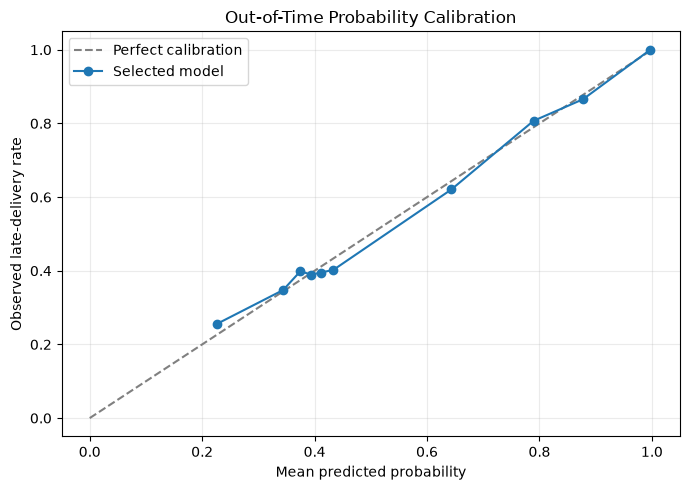

In [20]:
fold_prior_probabilities = {}

for fold in temporal_folds:
    fold_training_rate = development_df.loc[
        development_df["order_datetime"]
        < fold["train_end"],
        target_column
    ].mean()

    fold_prior_probabilities[
        fold["fold"]
    ] = fold_training_rate

oof_predictions["baseline_probability"] = (
    oof_predictions["prediction_fold"]
    .map(fold_prior_probabilities)
)

baseline_brier_score = brier_score_loss(
    oof_predictions["actual_late_delivery"],
    oof_predictions["baseline_probability"]
)

baseline_log_loss = log_loss(
    oof_predictions["actual_late_delivery"],
    oof_predictions["baseline_probability"]
)

print(
    "Baseline Brier score:",
    round(baseline_brier_score, 4)
)
print(
    "Model Brier score:",
    round(oof_brier_score, 4)
)
print(
    "Baseline log loss:",
    round(baseline_log_loss, 4)
)
print(
    "Model log loss:",
    round(oof_log_loss, 4)
)

oof_predictions["risk_decile"] = (
    pd.qcut(
        oof_predictions["predicted_probability"],
        q=10,
        labels=False,
        duplicates="drop"
    )
    + 1
)

calibration_table = (
    oof_predictions
    .groupby(
        "risk_decile",
        observed=True
    )
    .agg(
        order_count=("order_id", "size"),
        minimum_probability=(
            "predicted_probability",
            "min"
        ),
        maximum_probability=(
            "predicted_probability",
            "max"
        ),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        observed_late_rate=(
            "actual_late_delivery",
            "mean"
        )
    )
    .reset_index()
)

calibration_table["absolute_gap"] = (
    calibration_table["mean_predicted_probability"]
    - calibration_table["observed_late_rate"]
).abs()

expected_calibration_error = np.average(
    calibration_table["absolute_gap"],
    weights=calibration_table["order_count"]
)

display(calibration_table.round(4))

print(
    "Expected calibration error:",
    round(expected_calibration_error, 4)
)

plt.figure(figsize=(7, 5))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    calibration_table["mean_predicted_probability"],
    calibration_table["observed_late_rate"],
    marker="o",
    label="Selected model"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed late-delivery rate")
plt.title("Out-of-Time Probability Calibration")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Operational Threshold Scenarios

The selected model materially improves probability quality over the prevalence baseline and demonstrates a low expected calibration error. No additional probability calibration is applied.

Because intervention costs and operational capacity are not yet known, a universal threshold is not assumed. Instead, several decision policies are compared using pooled out-of-time predictions.

The final threshold should be selected jointly with business stakeholders based on the cost of missed late deliveries and the number of orders that can be reviewed.

In [21]:
oof_threshold_rows = []

for threshold in np.arange(0.20, 0.801, 0.01):
    predictions = (
        oof_predictions["predicted_probability"]
        >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        oof_predictions["actual_late_delivery"],
        predictions,
        labels=[0, 1]
    ).ravel()

    oof_threshold_rows.append({
        "threshold": threshold,
        "alert_rate_pct": predictions.mean() * 100,
        "precision": precision_score(
            oof_predictions["actual_late_delivery"],
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            oof_predictions["actual_late_delivery"],
            predictions,
            zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "balanced_accuracy": balanced_accuracy_score(
            oof_predictions["actual_late_delivery"],
            predictions
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

oof_threshold_results = pd.DataFrame(
    oof_threshold_rows
)

default_row = oof_threshold_results.loc[
    (
        oof_threshold_results["threshold"]
        - 0.50
    ).abs().idxmin()
]

best_balanced_row = (
    oof_threshold_results
    .sort_values(
        ["balanced_accuracy", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)

recall_70_row = (
    oof_threshold_results
    .loc[oof_threshold_results["recall"] >= 0.70]
    .sort_values(
        ["alert_rate_pct", "precision"],
        ascending=[True, False]
    )
    .iloc[0]
)

capacity_40_row = (
    oof_threshold_results
    .loc[
        oof_threshold_results["alert_rate_pct"]
        <= 40
    ]
    .sort_values(
        ["recall", "precision"],
        ascending=[False, False]
    )
    .iloc[0]
)

scenario_rows = []

for scenario_name, scenario_row in [
    ("Default threshold", default_row),
    ("Maximum balanced accuracy", best_balanced_row),
    ("Recall of at least 70%", recall_70_row),
    ("Maximum recall within 40% capacity", capacity_40_row)
]:
    row = scenario_row.to_dict()
    row["scenario"] = scenario_name
    scenario_rows.append(row)

threshold_scenarios = pd.DataFrame(
    scenario_rows
)[
    [
        "scenario",
        "threshold",
        "alert_rate_pct",
        "precision",
        "recall",
        "specificity",
        "balanced_accuracy",
        "false_positives",
        "false_negatives"
    ]
]

display(
    threshold_scenarios.round({
        "threshold": 2,
        "alert_rate_pct": 2,
        "precision": 4,
        "recall": 4,
        "specificity": 4,
        "balanced_accuracy": 4
    })
)

,scenario,threshold,alert_rate_pct,precision,recall,specificity,balanced_accuracy,false_positives,false_negatives
0,Default threshold,0.50,37.86,0.8479,0.5855,0.8726,0.7290,1795.0,7085.0
1,Maximum balanced accuracy,0.56,37.31,0.8543,0.5814,0.8797,0.7305,1695.0,7155.0
2,Recall of at least 70%,0.41,55.16,0.7061,0.7104,0.6411,0.6758,5055.0,4950.0
3,Maximum recall within 40% capacity,0.46,39.71,0.8264,0.5986,0.8474,0.7230,2150.0,6861.0


### Threshold Decision

A probability threshold of **0.50** is retained as the primary operating point. Optimizing balanced accuracy produced only a negligible improvement while slightly reducing late-delivery recall, which did not justify additional threshold tuning.

A pre-specified **high-recall scenario at 0.41** is also retained for business discussion. Historically, this scenario detected approximately 70% of late deliveries but required reviewing approximately 55% of orders.

Both thresholds are frozen before evaluating the locked test period. Test results will not be used to modify them.


In [22]:
selected_thresholds = {
    "Primary operating point": 0.50,
    "High-recall scenario": 0.41
}

final_model_specification = {
    "algorithm": "HistGradientBoostingClassifier",
    "feature_set": "Operational Core",
    "feature_count": len(model_features),
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "primary_threshold": 0.50,
    "high_recall_threshold": 0.41
}

display(
    pd.DataFrame(
        [final_model_specification]
    )
)

display(
    pd.DataFrame(
        selected_thresholds.items(),
        columns=["decision_policy", "threshold"]
    )
)

,algorithm,feature_set,feature_count,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,primary_threshold,high_recall_threshold
0,HistGradientBoostingClassifier,Operational Core,23,0.05,200,15,30,1.0,0.5,0.41


,decision_policy,threshold
0,Primary operating point,0.50
1,High-recall scenario,0.41


## 15. Locked Test Evaluation

All modeling decisions—including the feature set, algorithm, hyperparameters, and operating thresholds—were finalized before accessing the test period.

The selected pipeline is retrained on the complete development period and evaluated once on orders from July 2017 through January 2018.

Test results represent the final estimate of generalization performance and will not be used for further model or threshold tuning.

In [23]:
final_model = clone(selected_hist_pipeline)

final_model.fit(
    development_df[model_features],
    development_df[target_column]
)

test_probabilities = final_model.predict_proba(
    test_df[model_features]
)[:, 1]

development_late_rate = (
    development_df[target_column].mean()
)

baseline_test_probabilities = np.full(
    len(test_df),
    development_late_rate
)

test_probability_metrics = pd.DataFrame([
    {
        "model": "Prevalence baseline",
        "roc_auc": roc_auc_score(
            test_df[target_column],
            baseline_test_probabilities
        ),
        "average_precision": average_precision_score(
            test_df[target_column],
            baseline_test_probabilities
        ),
        "brier_score": brier_score_loss(
            test_df[target_column],
            baseline_test_probabilities
        ),
        "log_loss": log_loss(
            test_df[target_column],
            baseline_test_probabilities
        )
    },
    {
        "model": "Selected model",
        "roc_auc": roc_auc_score(
            test_df[target_column],
            test_probabilities
        ),
        "average_precision": average_precision_score(
            test_df[target_column],
            test_probabilities
        ),
        "brier_score": brier_score_loss(
            test_df[target_column],
            test_probabilities
        ),
        "log_loss": log_loss(
            test_df[target_column],
            test_probabilities
        )
    }
])

test_threshold_rows = []

for policy_name, threshold in selected_thresholds.items():
    test_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        test_df[target_column],
        test_predictions,
        labels=[0, 1]
    ).ravel()

    test_threshold_rows.append({
        "decision_policy": policy_name,
        "threshold": threshold,
        "alert_rate_pct": (
            test_predictions.mean() * 100
        ),
        "accuracy": accuracy_score(
            test_df[target_column],
            test_predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            test_df[target_column],
            test_predictions
        ),
        "precision": precision_score(
            test_df[target_column],
            test_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            test_df[target_column],
            test_predictions,
            zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "f1": f1_score(
            test_df[target_column],
            test_predictions,
            zero_division=0
        ),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    })

test_threshold_metrics = pd.DataFrame(
    test_threshold_rows
)

test_predictions_output = test_df[
    [
        "order_id",
        "order_datetime",
        target_column
    ]
].copy()

test_predictions_output["predicted_probability"] = (
    test_probabilities
)

print("Development rows:", len(development_df))
print("Test rows:", len(test_df))
print(
    "Test period:",
    test_df["order_datetime"].min(),
    "to",
    test_df["order_datetime"].max()
)

display(test_probability_metrics.round(4))

display(
    test_threshold_metrics.round({
        "threshold": 2,
        "alert_rate_pct": 2,
        "accuracy": 4,
        "balanced_accuracy": 4,
        "precision": 4,
        "recall": 4,
        "specificity": 4,
        "f1": 4
    })
)

Development rows: 52082
Test rows: 13670
Test period: 2017-07-01 00:07:00 to 2018-01-31 23:38:00


,model,roc_auc,average_precision,brier_score,log_loss
0,Prevalence baseline,0.5000,0.5504,0.2475,0.6881
1,Selected model,0.7725,0.8374,0.1827,0.5278


,decision_policy,threshold,alert_rate_pct,accuracy,balanced_accuracy,precision,recall,specificity,f1,true_negatives,false_positives,false_negatives,true_positives
0,Primary operating point,0.50,39.51,0.7189,0.7318,0.8408,0.6035,0.8601,0.7027,5286,860,2983,4541
1,High-recall scenario,0.41,62.28,0.6721,0.6613,0.6786,0.7678,0.5548,0.7205,3410,2736,1747,5777


## 16. Model Interpretation

Permutation importance is used to measure how much test ROC AUC decreases when each input feature is randomly disrupted.

The fitted model remains unchanged, and importance results are used exclusively for interpretation—not for additional model selection or tuning.

Permutation importance indicates predictive reliance rather than causality. Correlated variables may also share importance, causing their individual contributions to appear smaller.

,feature,mean_auc_decrease,importance_std
0,shipping_mode,0.2552,0.0044
1,order_hour,0.0461,0.0011
2,payment_type,0.0126,0.0014
3,order_country,0.0016,0.0016
4,primary_category_sales_share,0.0007,0.0008
5,gross_sales,0.0005,0.0003
6,total_item_quantity,0.0003,0.0009
7,net_sales,0.0002,0.0006
8,order_discount_rate,0.0001,0.0008
9,order_day_of_week,0.0001,0.0002


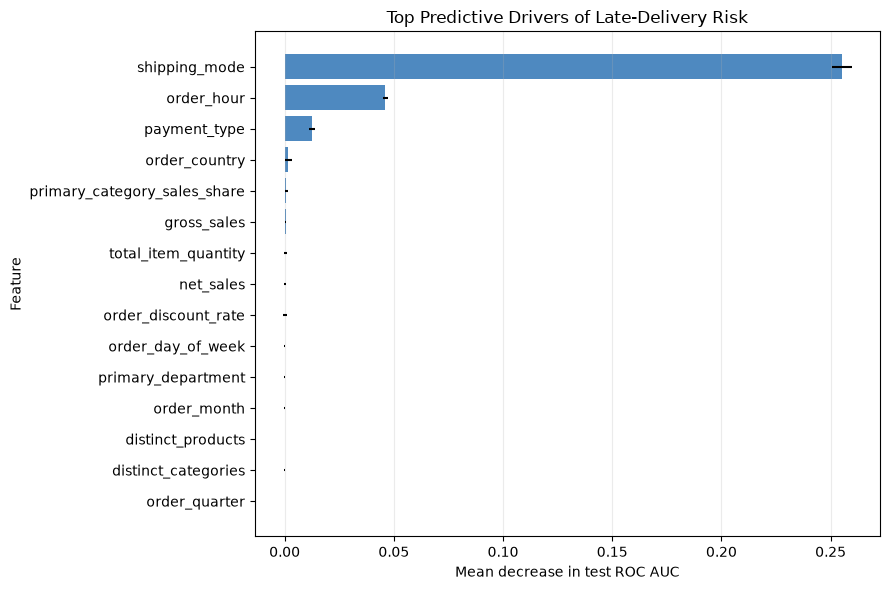

In [24]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    final_model,
    test_df[model_features],
    test_df[target_column],
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = (
    pd.DataFrame({
        "feature": model_features,
        "mean_auc_decrease": (
            permutation_results.importances_mean
        ),
        "importance_std": (
            permutation_results.importances_std
        )
    })
    .sort_values(
        "mean_auc_decrease",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance.round(4))

top_features = (
    feature_importance
    .head(15)
    .sort_values("mean_auc_decrease")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["mean_auc_decrease"],
    xerr=top_features["importance_std"],
    color="#2F75B5",
    alpha=0.85
)

plt.xlabel("Mean decrease in test ROC AUC")
plt.ylabel("Feature")
plt.title("Top Predictive Drivers of Late-Delivery Risk")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 17. Structural Feature-Dependence Audit

Shipping mode is known at order creation and is therefore operationally available. However, it also represents the scheduled delivery commitment used in the target definition.

A temporal sensitivity analysis compares the full operational model, a shipping-mode-only model, and a model that excludes shipping mode.

This analysis quantifies structural reliance and supports monitoring recommendations. It is diagnostic only and does not reopen model selection or use the test period for additional tuning.

In [25]:
sensitivity_feature_sets = {
    "Full Operational Core": {
        "categorical": categorical_features.copy(),
        "numeric": numeric_features.copy()
    },
    "Shipping Mode Only": {
        "categorical": ["shipping_mode"],
        "numeric": []
    },
    "Operational Core Without Shipping Mode": {
        "categorical": [
            feature
            for feature in categorical_features
            if feature != "shipping_mode"
        ],
        "numeric": numeric_features.copy()
    }
}

sensitivity_rows = []

for feature_set_name, features in (
    sensitivity_feature_sets.items()
):
    current_features = (
        features["categorical"]
        + features["numeric"]
    )

    for fold in temporal_folds:
        fold_train = development_df.loc[
            development_df["order_datetime"]
            < fold["train_end"]
        ]

        fold_validation = development_df.loc[
            (
                development_df["order_datetime"]
                >= fold["validation_start"]
            )
            & (
                development_df["order_datetime"]
                < fold["validation_end"]
            )
        ]

        sensitivity_model = build_hist_pipeline(
            features["categorical"],
            features["numeric"]
        )

        sensitivity_model.set_params(
            classifier__learning_rate=0.05,
            classifier__max_iter=200,
            classifier__max_leaf_nodes=15,
            classifier__min_samples_leaf=30,
            classifier__l2_regularization=1.0
        )

        sensitivity_model.fit(
            fold_train[current_features],
            fold_train[target_column]
        )

        sensitivity_probabilities = (
            sensitivity_model.predict_proba(
                fold_validation[current_features]
            )[:, 1]
        )

        sensitivity_rows.append({
            "feature_set": feature_set_name,
            "fold": fold["fold"],
            "feature_count": len(current_features),
            "roc_auc": roc_auc_score(
                fold_validation[target_column],
                sensitivity_probabilities
            ),
            "average_precision": average_precision_score(
                fold_validation[target_column],
                sensitivity_probabilities
            )
        })

sensitivity_results = pd.DataFrame(
    sensitivity_rows
)

sensitivity_summary = (
    sensitivity_results
    .groupby(
        ["feature_set", "feature_count"]
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        roc_auc_min=("roc_auc", "min"),
        average_precision_mean=(
            "average_precision",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "roc_auc_mean",
        ascending=False
    )
)

display(
    sensitivity_results.round(4)
)

display(
    sensitivity_summary.round(4)
)

,feature_set,fold,feature_count,roc_auc,average_precision
0,Full Operational Core,Fold 1,23,0.7638,0.8338
1,Full Operational Core,Fold 2,23,0.7778,0.8402
2,Full Operational Core,Fold 3,23,0.7606,0.8259
3,Shipping Mode Only,Fold 1,1,0.7247,0.7511
4,Shipping Mode Only,Fold 2,1,0.7284,0.7512
5,Shipping Mode Only,Fold 3,1,0.7239,0.7412
6,Operational Core Without Shipping Mode,Fold 1,22,0.5405,0.5872
7,Operational Core Without Shipping Mode,Fold 2,22,0.5568,0.5904
8,Operational Core Without Shipping Mode,Fold 3,22,0.5357,0.5701


,feature_set,feature_count,roc_auc_mean,roc_auc_std,roc_auc_min,average_precision_mean
0,Full Operational Core,23,0.7674,0.0091,0.7606,0.8333
2,Shipping Mode Only,1,0.7256,0.0024,0.7239,0.7478
1,Operational Core Without Shipping Mode,22,0.5443,0.0111,0.5357,0.5826


### Shipping-Mode Risk Profile

Shipping mode carries most of the model's predictive signal because it represents the scheduled service commitment used to determine whether a delivery is late.

Observed outcomes, predicted probabilities, alert rates, and recall are compared by shipping mode. These results describe predictive associations and operational performance; they do not establish causality.

,shipping_mode,order_count,actual_late_orders,observed_late_rate,mean_predicted_probability,primary_alert_rate,true_positives,false_negatives,recall
0,First Class,2081,1974,0.9486,0.9528,1.0000,1974,0,1.0000
1,Second Class,2700,2083,0.7715,0.7685,0.9993,2082,1,0.9995
2,Same Day,771,394,0.5110,0.5150,0.5383,394,0,1.0000
3,Standard Class,8118,3073,0.3785,0.3963,0.0255,91,2982,0.0296


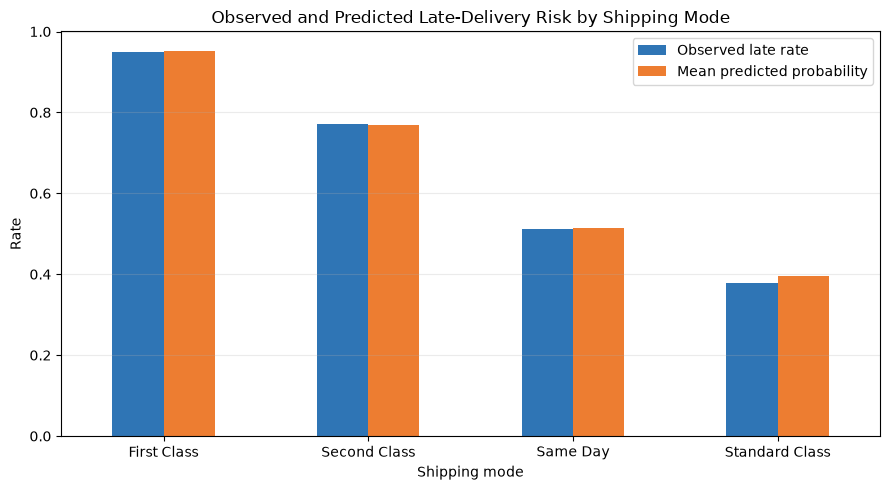

In [26]:
interpretation_df = test_df[
    [
        "order_id",
        "shipping_mode",
        "order_hour",
        "payment_type",
        target_column
    ]
].copy()

interpretation_df["predicted_probability"] = (
    test_probabilities
)

interpretation_df["primary_prediction"] = (
    test_probabilities >= 0.50
).astype(int)

interpretation_df["false_negative"] = (
    (
        interpretation_df[target_column] == 1
    )
    & (
        interpretation_df["primary_prediction"] == 0
    )
).astype(int)

interpretation_df["true_positive"] = (
    (
        interpretation_df[target_column] == 1
    )
    & (
        interpretation_df["primary_prediction"] == 1
    )
).astype(int)

shipping_mode_profile = (
    interpretation_df
    .groupby("shipping_mode")
    .agg(
        order_count=("order_id", "size"),
        actual_late_orders=(target_column, "sum"),
        observed_late_rate=(target_column, "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        primary_alert_rate=(
            "primary_prediction",
            "mean"
        ),
        true_positives=("true_positive", "sum"),
        false_negatives=("false_negative", "sum")
    )
    .reset_index()
)

shipping_mode_profile["recall"] = (
    shipping_mode_profile["true_positives"]
    / shipping_mode_profile["actual_late_orders"]
)

shipping_mode_profile = (
    shipping_mode_profile
    .sort_values(
        "observed_late_rate",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shipping_mode_profile.round({
        "observed_late_rate": 4,
        "mean_predicted_probability": 4,
        "primary_alert_rate": 4,
        "recall": 4
    })
)

shipping_mode_plot = (
    shipping_mode_profile
    .set_index("shipping_mode")
    [
        [
            "observed_late_rate",
            "mean_predicted_probability"
        ]
    ]
    .plot(
        kind="bar",
        figsize=(9, 5),
        color=["#2F75B5", "#ED7D31"]
    )
)

shipping_mode_plot.set_xlabel("Shipping mode")
shipping_mode_plot.set_ylabel("Rate")
shipping_mode_plot.set_title(
    "Observed and Predicted Late-Delivery Risk by Shipping Mode"
)
shipping_mode_plot.legend(
    ["Observed late rate", "Mean predicted probability"]
)
shipping_mode_plot.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


First Class and Second Class commitments show structurally high late-delivery rates, suggesting that service promises may be misaligned with operational capacity.

Standard Class contains most missed late deliveries and requires additional operational predictors or a differentiated intervention policy.

### Within-Mode Performance Audit

Overall discrimination may be driven primarily by differences between shipping modes rather than by the model's ability to rank individual orders within each mode.

Performance is therefore evaluated separately within each shipping-mode subgroup. This diagnostic analysis does not modify the finalized model or thresholds.

In [27]:
within_mode_rows = []

for shipping_mode, group in (
    interpretation_df.groupby("shipping_mode")
):
    actual = group[target_column]
    probabilities = group["predicted_probability"]
    predictions = group["primary_prediction"]

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    within_mode_rows.append({
        "shipping_mode": shipping_mode,
        "order_count": len(group),
        "observed_late_rate": actual.mean(),
        "roc_auc": (
            roc_auc_score(actual, probabilities)
            if actual.nunique() == 2
            else np.nan
            
        ),
        "average_precision": (
            average_precision_score(
                actual,
                probabilities
            )
            if actual.nunique() == 2
            else np.nan
        ),
        "alert_rate": predictions.mean(),
        "precision": precision_score(
            actual,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            actual,
            predictions,
            zero_division=0
        ),
        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),
        "balanced_accuracy": balanced_accuracy_score(
            actual,
            predictions
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

within_mode_performance = (
    pd.DataFrame(within_mode_rows)
    .sort_values(
        "order_count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    within_mode_performance.round({
        "observed_late_rate": 4,
        "roc_auc": 4,
        "average_precision": 4,
        "alert_rate": 4,
        "precision": 4,
        "recall": 4,
        "specificity": 4,
        "balanced_accuracy": 4
    })
)

,shipping_mode,order_count,observed_late_rate,roc_auc,average_precision,alert_rate,precision,recall,specificity,balanced_accuracy,false_positives,false_negatives
0,Standard Class,8118,0.3785,0.5254,0.3959,0.0255,0.4396,0.0296,0.9770,0.5033,116,2982
1,Second Class,2700,0.7715,0.5687,0.8005,0.9993,0.7717,0.9995,0.0016,0.5006,616,1
2,First Class,2081,0.9486,0.8719,0.9927,1.0000,0.9486,1.0000,0.0000,0.5000,107,0
3,Same Day,771,0.5110,0.9930,0.9930,0.5383,0.9494,1.0000,0.9443,0.9721,21,0


### Secondary Predictive-Driver Profiles

Order hour and payment type are examined because they were the second- and third-most important features in the permutation analysis.

Observed late-delivery rates are compared with mean predicted probabilities and order volumes. These profiles describe predictive associations and should not be interpreted as causal effects.

,order_hour,order_count,observed_late_rate,mean_predicted_probability,primary_alert_rate,absolute_calibration_gap
0,0,586,0.5273,0.5428,0.3720,0.0155
1,1,566,0.5212,0.5242,0.3728,0.0030
2,2,571,0.5254,0.5531,0.3888,0.0277
3,3,573,0.5183,0.5310,0.3351,0.0127
4,4,564,0.5266,0.5507,0.4007,0.0241
5,5,569,0.5395,0.5465,0.3726,0.0070
6,6,564,0.5426,0.5539,0.3954,0.0113
7,7,571,0.5359,0.5498,0.3993,0.0139
8,8,558,0.5054,0.5298,0.3746,0.0245
9,9,553,0.5280,0.5284,0.3743,0.0003


,payment_type,order_count,observed_late_rate,mean_predicted_probability,primary_alert_rate,absolute_calibration_gap
1,DEBIT,5231,0.5905,0.5901,0.4047,0.0004
2,PAYMENT,3146,0.5693,0.5846,0.4011,0.0153
0,CASH,1509,0.5613,0.5839,0.4003,0.0226
3,TRANSFER,3784,0.4749,0.4929,0.3747,0.0180


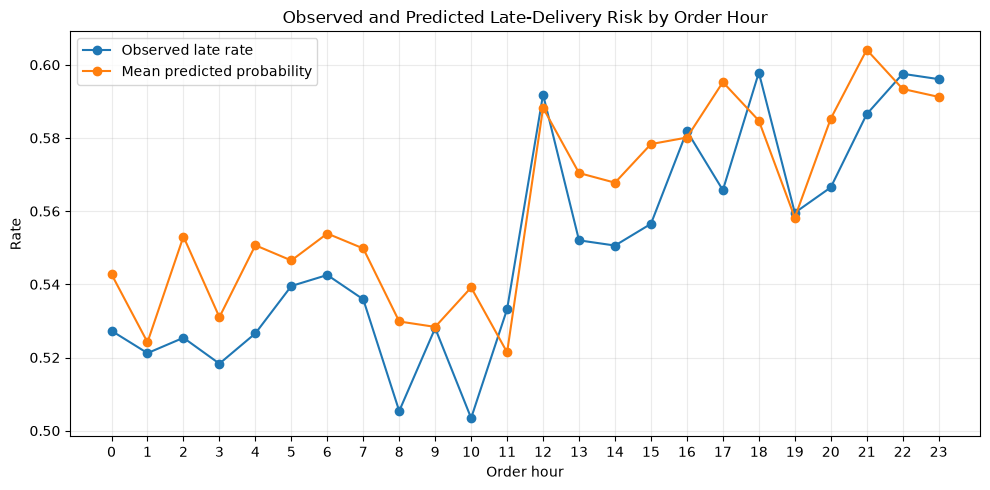

In [28]:
hour_profile = (
    interpretation_df
    .groupby("order_hour")
    .agg(
        order_count=("order_id", "size"),
        observed_late_rate=(target_column, "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        primary_alert_rate=(
            "primary_prediction",
            "mean"
        )
    )
    .reset_index()
    .sort_values("order_hour")
)

hour_profile["absolute_calibration_gap"] = (
    hour_profile["mean_predicted_probability"]
    - hour_profile["observed_late_rate"]
).abs()

payment_type_profile = (
    interpretation_df
    .groupby("payment_type")
    .agg(
        order_count=("order_id", "size"),
        observed_late_rate=(target_column, "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        primary_alert_rate=(
            "primary_prediction",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "observed_late_rate",
        ascending=False
    )
)

payment_type_profile["absolute_calibration_gap"] = (
    payment_type_profile[
        "mean_predicted_probability"
    ]
    - payment_type_profile["observed_late_rate"]
).abs()

display(
    hour_profile.round({
        "observed_late_rate": 4,
        "mean_predicted_probability": 4,
        "primary_alert_rate": 4,
        "absolute_calibration_gap": 4
    })
)

display(
    payment_type_profile.round({
        "observed_late_rate": 4,
        "mean_predicted_probability": 4,
        "primary_alert_rate": 4,
        "absolute_calibration_gap": 4
    })
)

plt.figure(figsize=(10, 5))

plt.plot(
    hour_profile["order_hour"],
    hour_profile["observed_late_rate"],
    marker="o",
    label="Observed late rate"
)

plt.plot(
    hour_profile["order_hour"],
    hour_profile["mean_predicted_probability"],
    marker="o",
    label="Mean predicted probability"
)

plt.xlabel("Order hour")
plt.ylabel("Rate")
plt.title("Observed and Predicted Late-Delivery Risk by Order Hour")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Shipping-Mode-Adjusted Hour Profile

The overall relationship between order hour and late-delivery risk may be influenced by changes in shipping-mode composition throughout the day.

Orders are grouped into six-hour periods and compared within each shipping mode. This stratified descriptive analysis helps distinguish a consistent time pattern from a shipping-mode mix effect, although it does not establish causality.

,shipping_mode,order_period,order_count,observed_late_rate,mean_predicted_probability
0,First Class,00:00–05:59,578,0.9377,0.9535
1,First Class,06:00–11:59,506,0.9486,0.9516
2,First Class,12:00–17:59,493,0.9412,0.9507
3,First Class,18:00–23:59,504,0.9683,0.9552
4,Same Day,00:00–05:59,171,0.0000,0.0446
5,Same Day,06:00–11:59,185,0.0000,0.0439
6,Same Day,12:00–17:59,191,0.9634,0.9214
7,Same Day,18:00–23:59,224,0.9375,0.9165
8,Second Class,00:00–05:59,641,0.7816,0.7682
9,Second Class,06:00–11:59,720,0.7722,0.7665


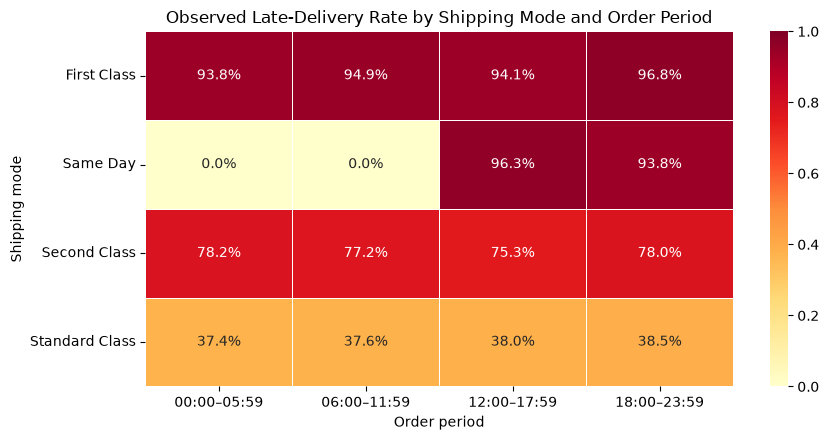

In [29]:
import seaborn as sns

interpretation_df["order_period"] = pd.cut(
    interpretation_df["order_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "00:00–05:59",
        "06:00–11:59",
        "12:00–17:59",
        "18:00–23:59"
    ]
)

stratified_hour_profile = (
    interpretation_df
    .groupby(
        ["shipping_mode", "order_period"],
        observed=True
    )
    .agg(
        order_count=("order_id", "size"),
        observed_late_rate=(target_column, "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        )
    )
    .reset_index()
)

display(
    stratified_hour_profile.round({
        "observed_late_rate": 4,
        "mean_predicted_probability": 4
    })
)

hour_mode_matrix = (
    stratified_hour_profile
    .pivot(
        index="shipping_mode",
        columns="order_period",
        values="observed_late_rate"
    )
)

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    hour_mode_matrix,
    annot=True,
    fmt=".1%",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.xlabel("Order period")
plt.ylabel("Shipping mode")
plt.title(
    "Observed Late-Delivery Rate by Shipping Mode and Order Period"
)
plt.tight_layout()
plt.show()

### Same-Day Cutoff Stability

The apparent midday cutoff pattern is evaluated across the predefined train, validation, and test periods.

This descriptive stability check determines whether the relationship is persistent over time rather than unique to the final test period. It does not alter the finalized model.

In [30]:
same_day_stability = df.loc[
    df["shipping_mode"] == "Same Day",
    [
        "order_id",
        "order_hour",
        "data_split",
        target_column
    ]
].copy()

same_day_stability["order_period"] = pd.cut(
    same_day_stability["order_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "00:00–05:59",
        "06:00–11:59",
        "12:00–17:59",
        "18:00–23:59"
    ]
)

same_day_stability_summary = (
    same_day_stability
    .groupby(
        ["data_split", "order_period"],
        observed=True
    )
    .agg(
        order_count=("order_id", "size"),
        late_order_count=(target_column, "sum"),
        observed_late_rate=(target_column, "mean")
    )
    .reset_index()
)

display(
    same_day_stability_summary.round({
        "observed_late_rate": 4
    })
)

,data_split,order_period,order_count,late_order_count,observed_late_rate
0,test,00:00–05:59,171,0,0.0000
1,test,06:00–11:59,185,0,0.0000
2,test,12:00–17:59,191,184,0.9634
3,test,18:00–23:59,224,210,0.9375
4,train,00:00–05:59,607,0,0.0000
5,train,06:00–11:59,612,0,0.0000
6,train,12:00–17:59,531,510,0.9605
7,train,18:00–23:59,498,482,0.9679
8,validation,00:00–05:59,152,0,0.0000
9,validation,06:00–11:59,117,0,0.0000


### Same-Day Cutoff Stability Conclusion

The midday pattern is consistent across the train, validation, and test periods.

Same Day orders placed before noon show an extremely low late-delivery rate, while orders placed from noon onward show a persistently high risk of delay. The stability across temporal partitions indicates that this is not an isolated test-period anomaly.

The pattern is consistent with an operational cutoff affecting the feasibility of the same-day service commitment. However, it should be validated with operational stakeholders before being treated as a causal business rule.

A transparent cutoff-based alert could complement the predictive model:

> Same Day orders placed at or after noon should receive immediate operational review.

This rule is documented as a business recommendation and is not used to modify the finalized model or its test results.

## 18. Model and Results Export

The finalized pipeline, model metadata, test predictions, evaluation metrics, feature importance, and diagnostic tables are exported as reproducible project artifacts.

These files support dashboard development, technical review, and future deployment without retraining or modifying the finalized model.

In [32]:
from pathlib import Path
import json
import joblib
import sklearn

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

artifacts_dir = project_root / "artifacts"
outputs_dir = project_root / "outputs"

artifacts_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

model_path = (
    artifacts_dir
    / "late_delivery_risk_model.joblib"
)

joblib.dump(
    final_model,
    model_path
)

print("Project root:", project_root)
print("Model exported to:", model_path)
print("Artifacts directory:", artifacts_dir)
print("Outputs directory:", outputs_dir)

Project root: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery
Model exported to: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\artifacts\late_delivery_risk_model.joblib
Artifacts directory: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\artifacts
Outputs directory: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\outputs


In [33]:
print("Model file exists:", model_path.exists())

if model_path.exists():
    print(
        "Model file size (MB):",
        round(model_path.stat().st_size / (1024 ** 2), 2)
    )

loaded_model = joblib.load(model_path)

loaded_probabilities = loaded_model.predict_proba(
    test_df[model_features]
)[:, 1]

maximum_probability_difference = np.max(
    np.abs(
        test_probabilities
        - loaded_probabilities
    )
)

print(
    "Maximum probability difference:",
    maximum_probability_difference
)

assert maximum_probability_difference < 1e-12

print("Model export validation: PASSED")

Model file exists: True
Model file size (MB): 0.48
Maximum probability difference: 0.0
Model export validation: PASSED


### Test Prediction Export

Test-period predictions are exported at order level for dashboard development and operational analysis.

The dataset includes the original model inputs, actual outcome, predicted probability, frozen decision policies, risk band, and primary-policy classification result.

In [35]:
test_predictions_export = test_df[
    [
        "order_id",
        "order_datetime",
        target_column
    ]
    + model_features
].copy()

test_predictions_export = (
    test_predictions_export
    .rename(
        columns={
            target_column: "actual_late_delivery"
        }
    )
)

test_predictions_export["predicted_probability"] = (
    test_probabilities
)

test_predictions_export["alert_threshold_050"] = (
    test_predictions_export["predicted_probability"]
    >= 0.50
).astype(int)

test_predictions_export["alert_threshold_041"] = (
    test_predictions_export["predicted_probability"]
    >= 0.41
).astype(int)

test_predictions_export["risk_band"] = pd.cut(
    test_predictions_export["predicted_probability"],
    bins=[0.00, 0.25, 0.50, 0.75, 1.00],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ],
    include_lowest=True
)

test_predictions_export["primary_policy_result"] = np.select(
    [
        (
            test_predictions_export["actual_late_delivery"] == 1
        )
        & (
            test_predictions_export["alert_threshold_050"] == 1
        ),
        (
            test_predictions_export["actual_late_delivery"] == 0
        )
        & (
            test_predictions_export["alert_threshold_050"] == 1
        ),
        (
            test_predictions_export["actual_late_delivery"] == 1
        )
        & (
            test_predictions_export["alert_threshold_050"] == 0
        )
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="True Negative"
)

predictions_path = (
    outputs_dir
    / "test_order_predictions.csv"
)

test_predictions_export.to_csv(
    predictions_path,
    index=False
)

print("Rows exported:", len(test_predictions_export))
print("Columns exported:", len(test_predictions_export.columns))
print("Predictions exported to:", predictions_path)

display(test_predictions_export.head())

Rows exported: 13670
Columns exported: 31
Predictions exported to: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\outputs\test_order_predictions.csv


,order_id,order_datetime,actual_late_delivery,payment_type,customer_segment,shipping_mode,market,order_region,order_country,primary_department,order_month,order_quarter,order_day_of_week,order_hour,is_weekend,order_line_count,total_item_quantity,distinct_products,distinct_categories,distinct_departments,gross_sales,total_discount,net_sales,weighted_avg_unit_price,order_discount_rate,primary_category_sales_share,predicted_probability,alert_threshold_050,alert_threshold_041,risk_band,primary_policy_result
52082,62477,2017-07-01 00:07:00,0,CASH,Corporate,Standard Class,Europe,Western Europe,Francia,Fan Shop,7,3,5,0,1,3,7,3,3,3,417.889996,57.840000,360.049999,59.698571,0.138410,0.598004,0.405154,0,0,Moderate,True Negative
52083,62478,2017-07-01 00:28:00,0,DEBIT,Consumer,Standard Class,Europe,Western Europe,Francia,Fan Shop,7,3,5,0,1,4,6,3,3,2,1149.950028,104.500000,1045.450028,191.658338,0.090874,0.695648,0.407315,0,0,Moderate,True Negative
52084,62479,2017-07-01 00:49:00,1,TRANSFER,Consumer,Standard Class,Europe,Western Europe,Francia,Fan Shop,7,3,5,0,1,3,10,3,3,2,459.860001,72.070000,387.789993,45.986000,0.156722,0.543426,0.309540,0,0,Moderate,False Negative
52085,62481,2017-07-01 01:31:00,0,DEBIT,Corporate,Standard Class,Europe,Western Europe,Francia,Footwear,7,3,5,1,1,1,2,1,1,1,199.979996,36.000000,163.979996,99.989998,0.180018,1.000000,0.414699,0,1,Moderate,True Negative
52086,62482,2017-07-01 01:52:00,0,DEBIT,Consumer,Standard Class,Europe,Western Europe,Francia,Fan Shop,7,3,5,1,1,4,9,3,3,3,1119.890015,180.390001,939.499992,124.432224,0.161078,0.535731,0.399941,0,0,Moderate,True Negative


In [36]:
export_tables = {
    "test_probability_metrics.csv": (
        test_probability_metrics
    ),
    "test_threshold_metrics.csv": (
        test_threshold_metrics
    ),
    "feature_importance.csv": (
        feature_importance
    ),
    "sensitivity_summary.csv": (
        sensitivity_summary
    ),
    "shipping_mode_profile.csv": (
        shipping_mode_profile
    ),
    "within_mode_performance.csv": (
        within_mode_performance
    ),
    "hour_profile.csv": (
        hour_profile
    ),
    "payment_type_profile.csv": (
        payment_type_profile
    ),
    "stratified_hour_profile.csv": (
        stratified_hour_profile
    ),
    "same_day_stability.csv": (
        same_day_stability_summary
    )
}

for file_name, table in export_tables.items():
    file_path = outputs_dir / file_name

    table.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"{file_name}: "
        f"{len(table)} rows exported"
    )

test_probability_metrics.csv: 2 rows exported
test_threshold_metrics.csv: 2 rows exported
feature_importance.csv: 23 rows exported
sensitivity_summary.csv: 3 rows exported
shipping_mode_profile.csv: 4 rows exported
within_mode_performance.csv: 4 rows exported
hour_profile.csv: 24 rows exported
payment_type_profile.csv: 4 rows exported
stratified_hour_profile.csv: 16 rows exported
same_day_stability.csv: 12 rows exported


In [37]:
import sys

selected_test_metrics = (
    test_probability_metrics
    .loc[
        test_probability_metrics["model"]
        == "Selected model"
    ]
    .iloc[0]
    .to_dict()
)

model_metadata = {
    "project_name": "Supply Chain Late Delivery Risk",
    "model_file": model_path.name,
    "model_class": (
        final_model
        .named_steps["classifier"]
        .__class__.__name__
    ),
    "problem_type": "Binary classification",
    "prediction_unit": "Order",
    "target": target_column,
    "target_definition": (
        "Actual shipping time exceeds "
        "scheduled shipping time"
    ),
    "development_rows": int(len(development_df)),
    "test_rows": int(len(test_df)),
    "test_period": {
        "start": (
            test_df["order_datetime"]
            .min()
            .isoformat()
        ),
        "end": (
            test_df["order_datetime"]
            .max()
            .isoformat()
        )
    },
    "feature_count": int(len(model_features)),
    "model_features": model_features,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "operating_thresholds": {
        str(policy): float(threshold)
        for policy, threshold
        in selected_thresholds.items()
    },
    "test_probability_metrics": {
        key: (
            float(value)
            if isinstance(value, (int, float, np.number))
            else value
        )
        for key, value
        in selected_test_metrics.items()
    },
    "software_versions": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    },
    "known_limitations": [
        (
            "Shipping mode contains most of the "
            "predictive signal."
        ),
        (
            "Standard Class shows limited "
            "within-group discrimination."
        ),
        (
            "A global threshold performs differently "
            "across shipping modes."
        ),
        (
            "Production use requires additional "
            "operational predictors and subgroup monitoring."
        )
    ]
}

metadata_path = (
    artifacts_dir
    / "model_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        model_metadata,
        metadata_file,
        indent=4,
        ensure_ascii=False
    )

with open(
    metadata_path,
    "r",
    encoding="utf-8"
) as metadata_file:
    validated_metadata = json.load(metadata_file)

print("Metadata exported to:", metadata_path)
print("Metadata validation: PASSED")
print("Feature count:", validated_metadata["feature_count"])
print(
    "Model class:",
    validated_metadata["model_class"]
)

Metadata exported to: c:\Users\Olimpia Santacruz\Documents\3.1416_2026\Supply_Chain_Late_Delivery\artifacts\model_metadata.json
Metadata validation: PASSED
Feature count: 23
Model class: HistGradientBoostingClassifier


In [38]:
expected_files = [
    model_path,
    metadata_path,
    predictions_path
] + [
    outputs_dir / file_name
    for file_name in export_tables
]

artifact_manifest = pd.DataFrame({
    "file_name": [
        path.name
        for path in expected_files
    ],
    "exists": [
        path.exists()
        for path in expected_files
    ],
    "size_kb": [
        round(path.stat().st_size / 1024, 2)
        if path.exists()
        else 0
        for path in expected_files
    ]
})

predictions_validation = pd.read_csv(
    predictions_path
)

assert artifact_manifest["exists"].all()
assert len(predictions_validation) == len(test_df)
assert predictions_validation["order_id"].is_unique
assert (
    predictions_validation["predicted_probability"]
    .notna()
    .all()
)
assert (
    predictions_validation["predicted_probability"]
    .between(0, 1)
    .all()
)

display(artifact_manifest)

print("Prediction rows:", len(predictions_validation))
print(
    "Unique order IDs:",
    predictions_validation["order_id"].nunique()
)
print("Export quality control: PASSED")

,file_name,exists,size_kb
0,late_delivery_risk_model.joblib,True,488.38
1,model_metadata.json,True,2.78
2,test_order_predictions.csv,True,3225.83
3,test_probability_metrics.csv,True,0.23
4,test_threshold_metrics.csv,True,0.51
5,feature_importance.csv,True,1.35
6,sensitivity_summary.csv,True,0.40
7,shipping_mode_profile.csv,True,0.52
8,within_mode_performance.csv,True,0.78
9,hour_profile.csv,True,2.13


Prediction rows: 13670
Unique order IDs: 13670
Export quality control: PASSED


## 19. Final Modeling Conclusion

The finalized late-delivery risk pipeline was trained on the complete development period and evaluated once on the previously blocked test period.

The model achieved a test ROC AUC of 0.7725 and average precision of 0.8374, demonstrating stable temporal generalization. The primary 0.50 threshold provides high precision, while the 0.41 scenario increases late-delivery coverage at the cost of additional operational alerts.

Interpretability and subgroup audits identified shipping mode as the dominant predictive driver. Performance varies substantially across service modes, with Standard Class accounting for nearly all missed late deliveries and Same Day showing a stable midday cutoff pattern.

The model is suitable as a validated risk-ranking prototype. Production deployment would require additional operational predictors, shipping-mode-level monitoring, and prospective validation of differentiated decision policies.

The trained pipeline, metadata, order-level test predictions, performance metrics, feature importance, and diagnostic tables were successfully exported and validated.